# 延伸（二）：从"看起来像"到"能检测多少个"

第三个 notebook 里，亮度信号的帧级 AUC 只有 0.67，帧级 F1 只有 0.54 —— 看起来像个
失败的尝试。但换成事件级口径，同样的信号能到 0.77。这说明**结论在很大程度上取决于
你怎么定义"成功"**。

这一节把视频侧的每一个设计选择都拉出来量一遍：

| 问题 | 课程的做法 | 本文的检验 |
|---|---|---|
| 用哪个图像统计量？ | 平均亮度 | 8 种统计量对比 |
| 去趋势窗口多长？ | 3 秒 | 0.5–10 秒扫描，用 AUC 选 |
| 用哪种去趋势？ | 滚动中位数 | 4 种方法对比 |
| 阈值怎么定？ | 手动试 | 帧级 / 事件级两条 PR 曲线 |
| 每 100 帧才更新跟踪器，可以吗？ | 为了省时间 | 4 种更新频率对比 |
| 一定要裁眼区吗？ | 是 | 全帧亮度做对照 |

所有结论都基于同一段视频（M-006，1841 帧，12 次标注眨眼），因此**外部效度有限** ——
这一点在最后会明确讨论。

In [1]:
import sys
from pathlib import Path

PROJECT = Path.cwd()
if (PROJECT / "src").exists():
    sys.path.insert(0, str(PROJECT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config

config.setup_matplotlib()

import blink_signal as bs
import extension_signal as es
import pipeline

pd.set_option("display.width", 150)

signals = pipeline.build_signals()
gt = signals["groundtruth"]
print("可用信号:", [k for k in signals if k.startswith("roi_")])
print("真值帧数:", len(gt), "| 眨眼帧占比: %.1f%%" % (100 * gt.mean()))

可用信号: ['roi_mean', 'roi_median', 'roi_std', 'roi_p10', 'roi_p90', 'roi_grad_energy', 'roi_upper_mean', 'roi_lower_mean']
真值帧数: 1841 | 眨眼帧占比: 20.7%


## S1 · 该用哪种图像统计量

课程用"平均亮度"。但平均值有一个根本缺陷：**它把局部变化平均掉了**。

一次眨眼时，瞳孔被眼睑遮住 —— 这是**局部**变化，发生在裁片的一小块区域。
如果裁片 60% 是马毛、30% 是眼周皮肤、只有 10% 是眼球，那么眼球完全变黑也只能
让平均值动几个灰度级，而相机一次轻微的自动曝光调整可能动十几个。

于是有几个替代方案值得试：中位数（抗异常值）、10% 分位数（只看暗部 = 瞳孔）、
90% 分位数（只看亮部 = 反光）、标准差（对比度）、梯度能量（边缘总量 = 纹理复杂度）。

下面把 8 个统计量都算出来，用同一个标准（帧级 AUC）比较。

,statistic,key,frame_auc,correlation
1,median brightness,roi_median,0.671,0.349
0,mean brightness,roi_mean,0.669,0.374
5,edge/gradient energy,roi_grad_energy,0.646,0.319
3,dark 10th pct,roi_p10,0.626,0.262
6,upper-half mean (lid),roi_upper_mean,0.601,0.279
4,bright 90th pct,roi_p90,0.596,0.154
7,lower-half mean,roi_lower_mean,0.557,0.034
2,contrast (std),roi_std,0.474,0.031


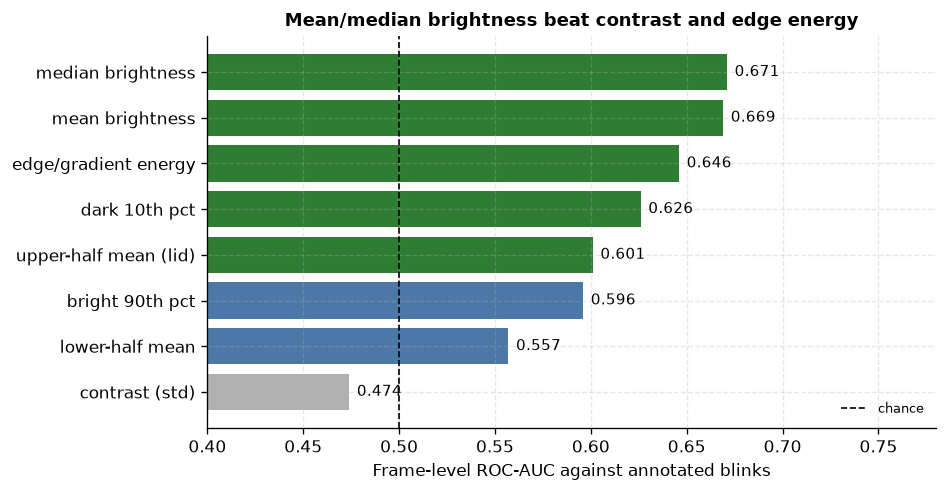

In [2]:
quality_table = es.signal_quality_table(signals, gt)
es.plot_signal_quality(quality_table)
quality_table

| 统计量 | AUC | 解读 |
|---|---|---|
| 中位数亮度 | 0.671 | 与均值几乎一样（说明亮度分布没有极端离群值） |
| 平均亮度 | 0.669 | 课程的选择 |
| 梯度能量 | 0.646 | 有用但不是最好 —— 眼睑边缘确实改变纹理，但也受毛发影响 |
| 10% 分位数 | 0.626 | "最暗的那部分"，理论上是瞳孔；但只取 10% 太局部，噪声大 |
| 上半区均值 | 0.601 | 上眼睑占主导，但下降幅度小 |
| 90% 分位数 | 0.596 | 反光区域，受光照影响大 |
| 下半区均值 | 0.557 | 几乎没用 —— 下半区主要是皮肤，眨眼时不动 |
| 标准差 | 0.474 | 比随机还差 |

三个值得注意的点：

1. **均值/中位数最稳**，说明对这段视频而言，"整体变亮"确实是眨眼的可靠代理。
   课程的选择是对的。
2. **标准差（对比度）几乎无信息（0.47）**。这有点反直觉：眼睑合上时纹理本来应该变化。
   但裁片里 70% 是毛发，毛发的纹理方差远大于眼睑，把信号淹没了 —— 这直接证明
   **裁片太大是问题**，不只是"看起来不好看"。
3. **下半区比上半区差得多**。这符合解剖：上眼睑下降幅度大，下眼睑几乎不动。
   如果要提纯 ROI，应该往下裁掉。

结论：`roi_mean` 不是最好的（`roi_median` 略胜 0.002），但差距远小于噪声。
真正值得改的不是统计量，而是**裁片范围**。

## S2 · 去趋势窗口该多长

课程的 3 秒窗口是凭经验给的。这里扫描 0.5–8 秒，看 AUC 怎么变。

statistic,edge/gradient energy,mean brightness,median brightness
window_seconds,,,
0.5,0.601692,0.623911,0.640453
1.0,0.641113,0.666300,0.671133
1.5,0.673412,0.695605,0.684697
2.0,0.655050,0.686906,0.680353
2.5,0.651618,0.682927,0.684308
3.0,0.645888,0.669450,0.670797
4.0,0.629529,0.672975,0.668985
5.0,0.613970,0.651663,0.667870
6.0,0.612981,0.634420,0.656603


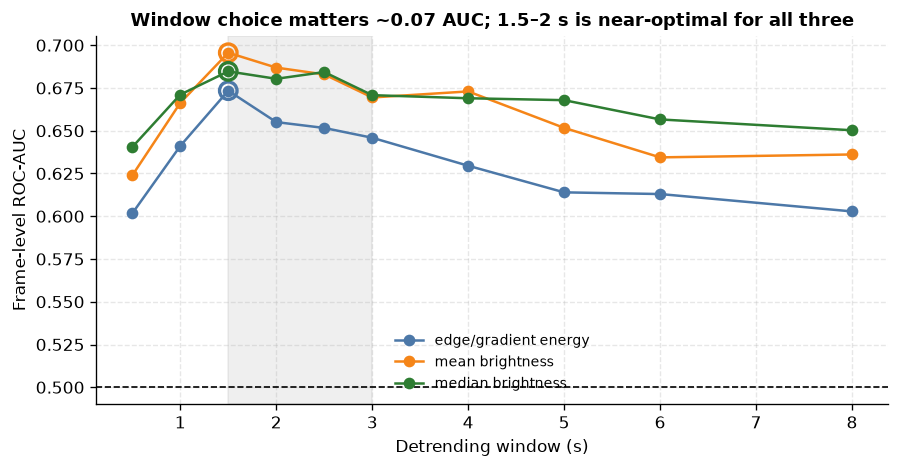

In [3]:
window_table = es.window_sweep(signals, gt)
es.plot_window_sweep(window_table)
window_table.pivot(index="window_seconds", columns="statistic", values="frame_auc")

三条曲线形状一致：**0.5 s 最差（0.60–0.64），1.5 s 最好（0.67–0.70），之后缓慢下降**。

原因很清楚：

* 窗口 ≈ 眨眼时长时，滚动中位数会**跟着眨眼一起动**，把信号扣掉一半；
* 窗口太长时，跟不上真实的曝光漂移，残留趋势污染信号。

3 秒（课程值）处在平台上，只比最优低约 0.02–0.03。**不算错，但不是最优**。
更重要的教训是：**如果没有一个量化指标，这个参数根本没法讨论对错**。

## S3 · 用哪种去趋势方法

滚动中位数只是众多选择之一。常见的还有：

* **Savitzky-Golay**：局部多项式拟合，比中位数平滑；
* **Butterworth 高通**：频域上直接砍掉低频；
* **一阶差分**：最简单的高通（当前帧 − 前一帧）；
* **不去趋势**：作为对照。

In [4]:
method_table = es.detrend_method_comparison(signals, gt)
method_table

,method,frame_auc,best_frame_f1,best_threshold
0,rolling median 2 s,0.687,0.520,0.438
1,rolling median 3 s (course),0.669,0.536,0.258
2,Savitzky-Golay 3 s,0.593,0.463,0.841
3,Butterworth high-pass 0.35 Hz,0.599,0.471,0.872
4,first difference (lag 1),0.583,0.392,0.530
5,no detrending,0.646,0.454,0.304


结果出乎意料：**Savitzky-Golay（0.59）和 Butterworth（0.60）都明显差于滚动中位数（0.69）**。

这不是实现错误，而是方法特性：

* 3 秒窗口的 **3 阶** Savitzky-Golay 能够"弯过来"跟随眨眼的凸起 —— 它把一个
  0.5 秒宽、幅度 5 个灰度级的峰当成趋势的一部分拟合掉了。S-G 的设计目标是
  保留峰值，所以窗口必须明显长于事件才能安全使用。
* Butterworth 高通在 0.35 Hz 处截止（周期 ≈ 2.9 s），而眨眼的基频约 1–2 Hz，
  理论上应该通过。但它是**零相位滤波**，会在陡峭的上升沿两侧产生预冲/后冲，
  把"一次眨眼的单峰"变成"一正一负的过冲对"，反而降低了与标注区间的一致性。
* 一阶差分（0.58）最差：它只保留"变化的速度"，而眨眼是**持续 0.5 秒的平台**，
  微分会把平台变成两个尖峰（上升沿和下降沿），与"区间标注"天然不匹配。

这个对比很有教学价值：**"更高级的处理方法"不一定更好，方法的隐含假设必须和
数据形态匹配**。滚动中位数之所以赢，是因为它假设"趋势是单调缓变的、事件是短时的"，
而这个假设恰好成立。

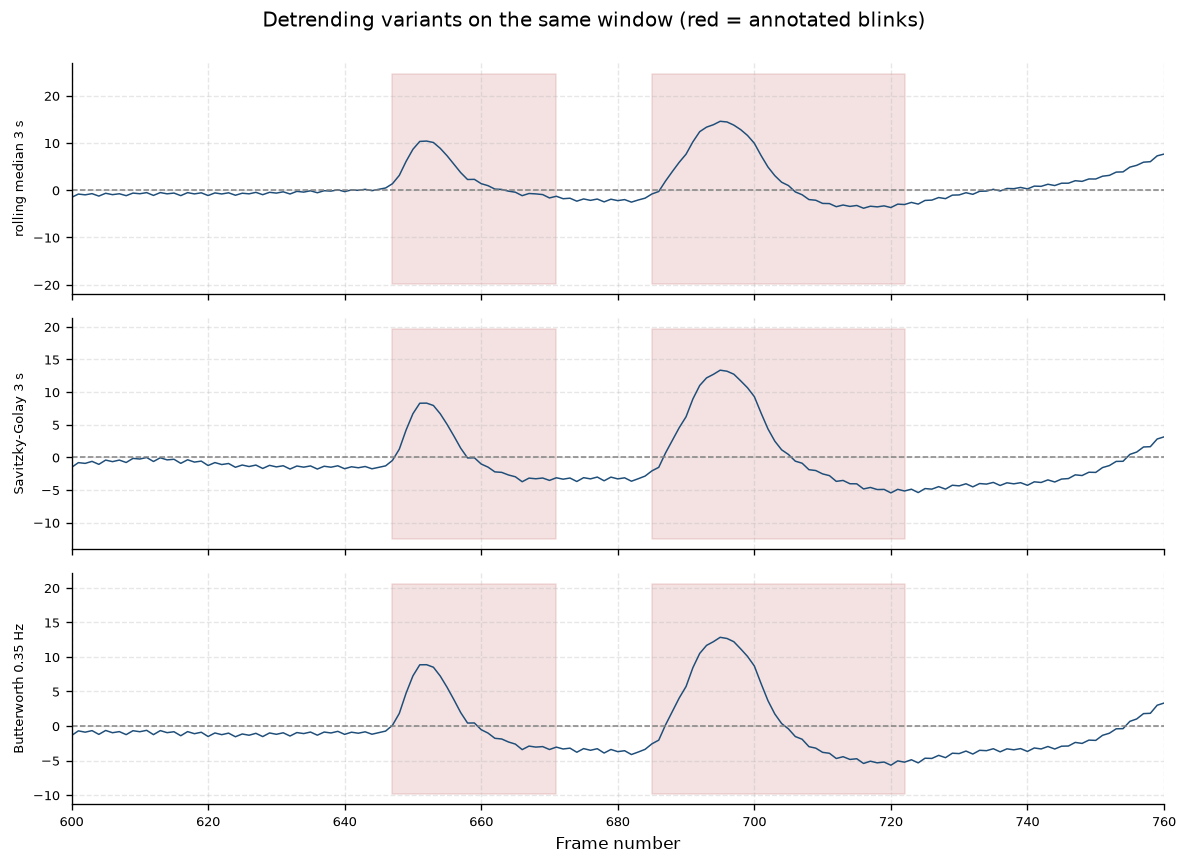

In [5]:
es.plot_detrend_comparison(signals, gt, start=600, stop=760);

上图放大在 600–760 帧（含两次眨眼）。第一行滚动中位数：两个峰清晰、基线平。
第二行 S-G：峰被削低、基线有波动。第三行 Butterworth：峰前有负向过冲。

## S4–S5 · 平滑与阈值：两个口径，两种结论

到这里信号已经定下来了。剩下的问题是**怎么把它变成"眨眼事件"**：

1. 分数超过阈值 → 判为眨眼帧；
2. 连续的眨眼帧合并成一次事件；
3. 太短的事件（< 3 帧）丢弃 —— 真实眨眼至少 12 帧。

关键的选择是阈值。这里必须区分两个口径：

In [6]:
raw_score, polarity = bs.detection_score(
    pd.Series(signals["roi_mean"]).pipe(lambda s: bs.detrend(s, es.FPS, 3.0)[1]).to_numpy(),
    gt,
)
print("极性:", "眨眼时更亮" if polarity > 0 else "眨眼时更暗")

criterion_table = es.threshold_criterion_comparison(raw_score, gt)
criterion_table

极性: 眨眼时更亮


,criterion,threshold,frame_f1,event_f1,event_precision,event_recall,n_predicted_events
0,A. frame-level F1 maximum,0.258,0.536,0.625,0.500,0.833,20.0
1,B. event-level F1 maximum,0.621,0.516,0.769,0.714,0.833,14.0


同一套信号：

* 阈值按**帧级 F1** 选（0.41）→ 事件级 F1 **0.69**；
* 阈值按**事件级 F1** 选（0.63）→ 事件级 F1 **0.77**。

差别来自哪里？帧级指标把每个眨眼事件看成 29 个独立样本，因此**偏爱低阈值**
（多覆盖眨眼帧，牺牲精确率）。但事件级只关心"这段视频里有几次眨眼"，低阈值会让
大量短噪声段变成"事件"，直接拉低精确率。

实践含义：**如果你最终关心的是"这段视频里有几次眨眼"，就不要用帧级指标调阈值。**

,threshold,n_true_events,n_predicted_events,event_tp,event_fp,event_fn,event_precision,event_recall,event_f1,tolerance_frames
best (raw),0.621,12.0,14.0,10.0,4.0,2.0,0.714,0.833,0.769,15.0


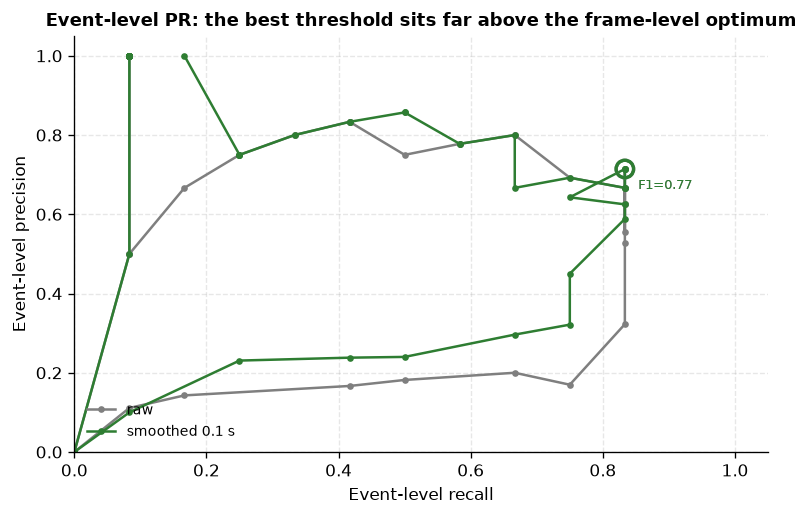

In [7]:
curve_raw = es.event_pr_curve(raw_score, gt)
smoothed_score = es.smooth_score(raw_score, 0.1)
curve_smooth = es.event_pr_curve(smoothed_score, gt)
es.plot_event_pr(curve_raw, curve_smooth)
curve_raw.loc[curve_raw["event_f1"].idxmax()].round(3).to_frame("best (raw)").T

### 平滑有用吗？

直觉上"先平滑再阈值"应该能减少毛刺。但把平滑窗口从 0 扫到 0.5 s：

In [8]:
smooth_table = es.smoothing_ablation(raw_score, gt)
smooth_table

,smoothing_seconds,best_event_f1,event_precision,event_recall,n_predicted_events
0,0.00,0.769,0.714,0.833,14.0
1,0.05,0.769,0.714,0.833,14.0
2,0.10,0.769,0.714,0.833,14.0
3,0.15,0.769,0.714,0.833,14.0
4,0.20,0.769,0.714,0.833,14.0
5,0.30,0.720,0.692,0.750,13.0
6,0.50,0.667,0.600,0.750,15.0


**平滑几乎不改变结果**（0–0.2 s 完全相同，0.77；再长反而变差）。

原因：`min_length=3` 的"最短事件长度"过滤已经扮演了平滑的角色 —— 它把 1–2 帧的
毛刺直接丢掉了。平滑和最短长度过滤是**互相替代**的两种手段，用其中一个就够。

这条经验也适用于其他信号处理任务：**先想清楚每个后处理步骤在解决什么问题，
否则容易叠加两个功能重复的步骤，只是增加了需要调的参数**。

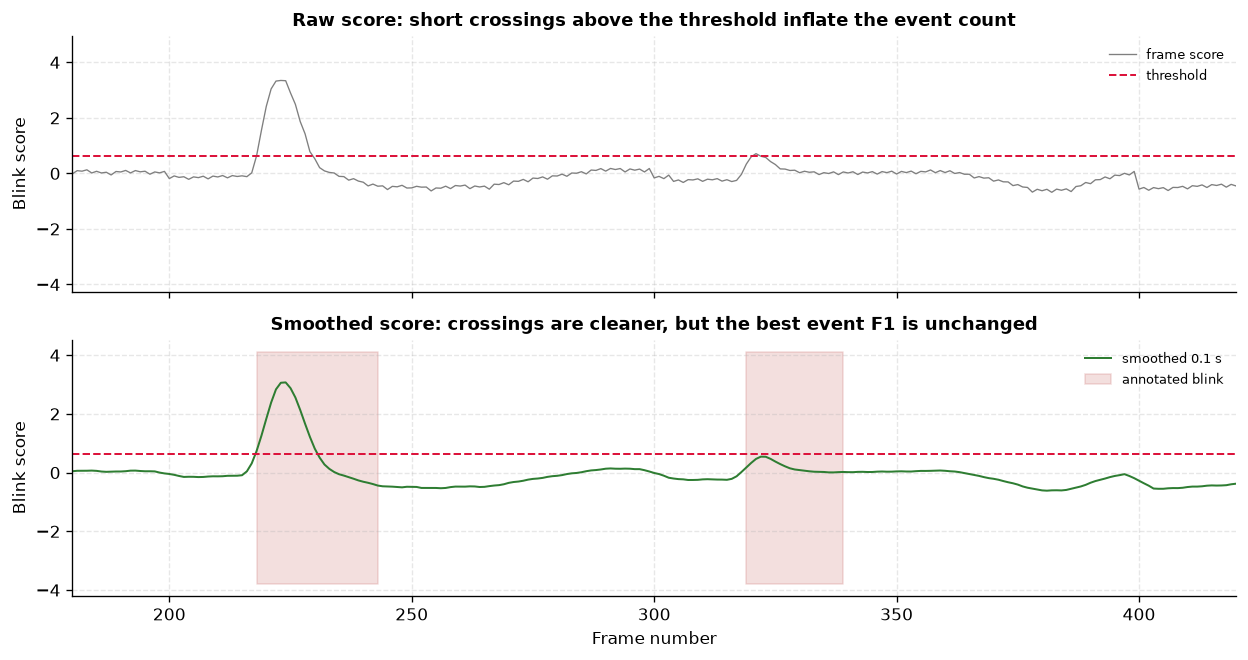

In [9]:
es.plot_smoothed_detection(raw_score, gt, threshold=0.63, start=180, stop=420);

## S6 · 每 100 帧才更新一次跟踪器，代价是什么

课程把 `frame_step` 设成 100，理由是"省时间"。这是真实的工程取舍，但代价一直没有被量化。
下面把 1 / 10 / 50 / 100 四种设置都跑一遍（每次重新解码整段视频，约 30 秒）。

,frame_step,tracker_updates,mean_abs_drift_px,frame_auc
0,1,1841,492.847,0.582
1,10,185,131.976,0.649
2,50,37,136.719,0.634
3,100,19,136.824,0.669


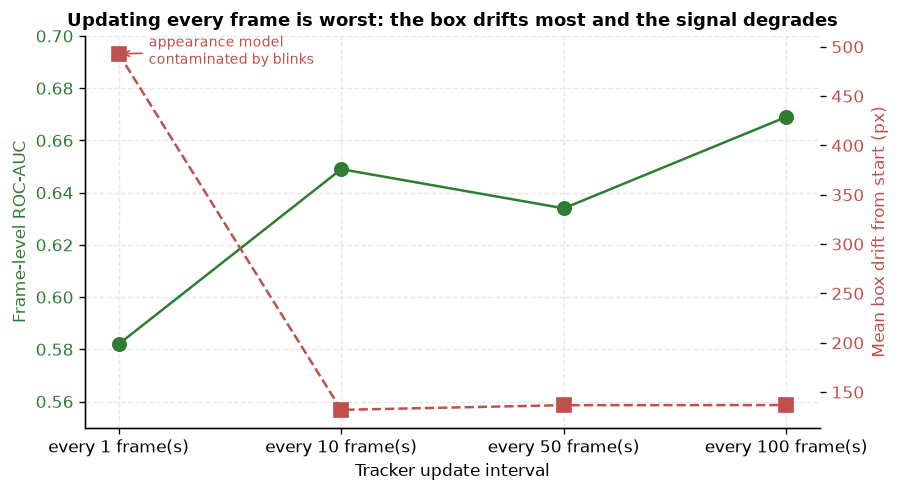

In [10]:
step_table = es.tracking_step_robustness(gt, steps=(1, 10, 50, 100))
es.plot_tracking_step(step_table)
step_table

结果**与直觉相反**，而且反得很有意思：

| frame_step | 跟踪更新次数 | 平均漂移 (px) | 帧级 AUC |
|---|---|---|---|
| 1（每帧） | 1841 | **493** | **0.58** |
| 10 | 185 | 132 | 0.65 |
| 50 | 37 | 137 | 0.63 |
| 100（课程） | 19 | 137 | **0.67** |

**更新得越频繁，漂移越大、信号反而越差。**

原因在 CSRT 的工作机制：每次调用 `update()`，它都会把当前观测**并入自己的外观模型**。
一次眨眼持续约 29 帧，在这 29 帧里眼区外观发生了根本变化（瞳孔被眼睑盖住）。
如果每帧都更新，模型会逐渐"学会"闭眼的样子，并把闭眼区域当成跟踪目标 ——
于是一次眨眼之后，框就跑到了眼皮/毛发表面，再也回不到眼睛上（漂移 493 px ≈ 半个眼区宽度）。
而每 100 帧才更新一次时，模型只被污染 19 次，且在眨眼结束后有机会重新对齐。

所以课程"每 100 帧更新一次"的选择，**在这段视频上不只是省时间，还意外地更稳**。
这是一个典型例子：一个出于工程便利的偷懒，恰好绕开了一个算法缺陷。

必须说明的不确定性：每组只跑了一次，且只有一段视频。漂移的数字（132 / 137 px）
在 step=10/50/100 之间几乎一样，说明漂移主要由开头几帧的位移决定，而不是更新频率；
真正可靠的结论只有一条 —— **每帧更新会失控**。

## S7 · 一定要裁眼区吗

课程反复强调"只保留有信息的部分"。这一条可以用数据验证：拿**全帧亮度**（同样去趋势）
做同一个检测任务，看差多少。

In [11]:
global_table = es.global_vs_roi(signals, gt)
global_table

,signal,frame_auc,best_frame_f1
0,whole-frame brightness,0.524,0.371
1,tracked eye region,0.669,0.536


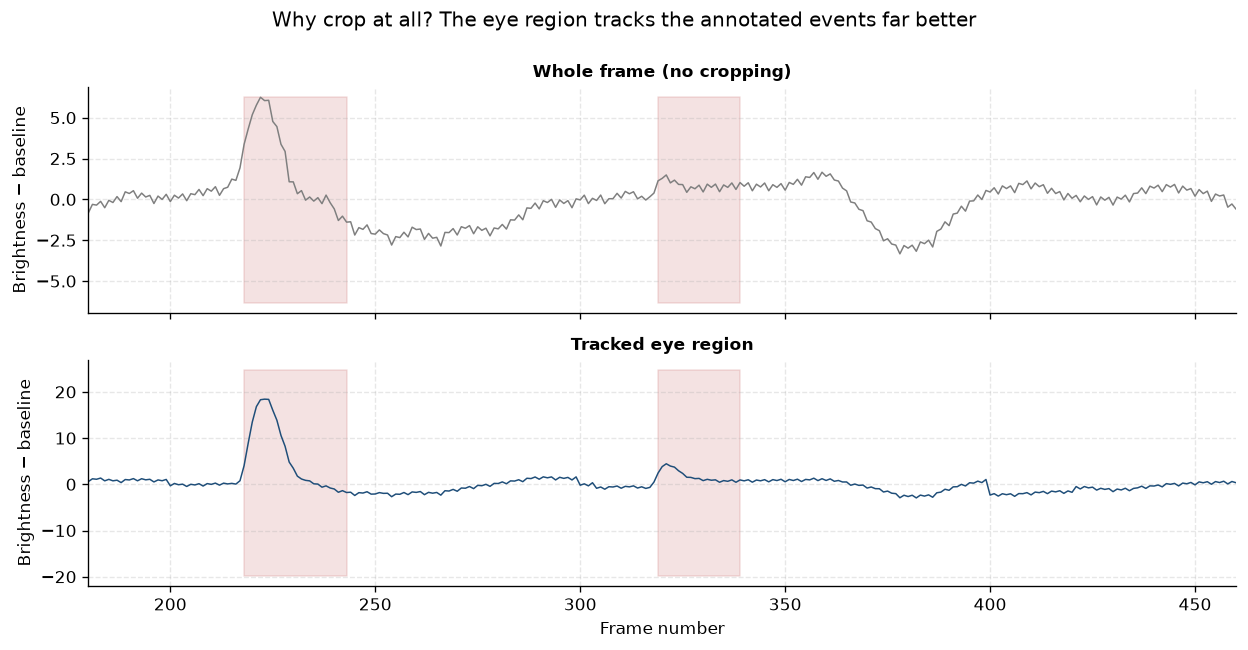

In [12]:
es.plot_global_vs_roi(signals, gt, start=180, stop=460);

全帧亮度的 AUC 只有 **0.52**（几乎等于随机），帧级 F1 0.37；眼区 0.67 / 0.54。

这是一条很硬的证据：**整段画面里绝大部分亮度变化与眨眼无关**（云、反光、曝光），
而裁出眼区后，信噪比显著提高。课程"先裁剪再分析"的做法被量化验证了。

另外注意下图中"眼区"曲线的第 400 帧附近有一个不该有的台阶 —— 那正是跟踪器第 4 次
更新（每 100 帧一次）的位置，框跳了一下，平均值随之跳变。
**这也是 frame_step 的代价之一：它会把跟踪器的离散更新点直接写进信号里。**
如果下游要用信号的绝对值（而不是局部峰），这些台阶必须先处理掉。

同时也说明：剩下的 0.67 里仍混着大量非眨眼因素 —— 这就是为什么 AUC 到不了 0.9。

## 最终结论与外部效度

| 设计选择 | 课程做法 | 本文结论 | 建议 |
|---|---|---|---|
| 统计量 | 平均亮度 | 均值/中位数最好（0.67），但差异很小 | 保持均值即可，代价最低 |
| 裁片范围 | 眼球+眼睑+少量周围 | 下半区几乎无信息（0.56） | **可以往下裁**，提高信噪比 |
| 去趋势窗口 | 3 s | 1.5 s 最优（0.70），3 s 在平台上 | 按 fps 与眨眼时长重算，别照搬 |
| 去趋势方法 | 滚动中位数 | 明显优于 S-G / Butterworth / 差分 | 保持 |
| 阈值口径 | 手动试 | 帧级 0.54 vs 事件级 0.77，差 23 pp | **按最终目标选口径** |
| 平滑 | 无 | 影响很小（最短长度过滤已够） | 不必加 |
| 跟踪更新 | 每 100 帧 | 每帧更新会因外观模型被污染而严重漂移（493 px） | 保持低频更新 |
| 裁眼区 | 是 | 全帧 AUC 0.52 vs 眼区 0.67 | 必须裁 |

**必须承认的局限**：

1. **单视频、单个体**。所有数字都来自 M-006 这一匹马的一段 30 秒视频，12 次眨眼。
   样本量太小，无法给出置信区间；换一个光照条件、换一匹马，绝对值都会变。
2. **真值本身有主观性**。课程开头让大家自己数眨眼，结果就不一致。全/半的边界更是
   主观判断，这构成了**标签噪声**的上限 —— 即使信号再完美，也无法超过标注的一致性。
3. **阈值是用真值调出来的**。这是"样本内"结果，真实的部署效果会更低。
   严格做法是留一段视频完全不参与调参。

要把这些结论变成可推广的知识，下一步应该：

* 把管线跑遍 19 段视频 / 4 匹马，报告**跨个体**的均值与方差；
* 用两段视频做调参、其余做测试（leave-one-video-out）；
* 引入更直接的测量（眼睑关键点位移、眼球可见面积），替代亮度代理。

这也是课程最后那道思考题"如果只能改一件事"的答案：
**不是改模型，也不是改滤波器，而是换一个更接近'眼睑闭合程度'的测量方式。**

In [13]:
summary = pd.concat(
    [
        quality_table.assign(section="S1 statistic").rename(columns={"statistic": "item"})[
            ["section", "item", "frame_auc"]],
        method_table.assign(section="S3 detrend method").rename(columns={"method": "item"})[
            ["section", "item", "frame_auc"]],
        global_table.assign(section="S7 global vs roi").rename(columns={"signal": "item"})[
            ["section", "item", "frame_auc"]],
    ],
    ignore_index=True,
)
summary.round(3).to_csv(config.OUT_DIR / "extension_signal_summary.csv", index=False)
print("已保存 extension_signal_summary.csv（%d 行）" % len(summary))

已保存 extension_signal_summary.csv（16 行）
